<a href="https://colab.research.google.com/github/ryhanhkwshky821-cpu/Untitled18.ipynb/blob/main/House_Price_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

base = "https://raw.githubusercontent.com/Rswcf/houseprices_kaggle/master/"

train = pd.read_csv(base + "train.csv")
test = pd.read_csv(base + "test.csv")

print("Train:", train.shape)
print("Test:", test.shape)

train.head()

Train: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# جدا کردن قیمت خانه
y = train["SalePrice"]

# ترکیب داده‌های آموزش و تست
data = pd.concat([train.drop("SalePrice", axis=1), test])

# تبدیل داده‌های متنی به عددی
data = pd.get_dummies(data)

# جایگزینی مقادیر خالی
data = data.fillna(data.median())

# جداسازی داده‌های آموزش و تست
X = data.iloc[:len(train)]
X_test = data.iloc[len(train):]

# نرمال‌سازی
scaler = StandardScaler()
X = scaler.fit_transform(X)
X_test = scaler.transform(X_test)

# تقسیم داده‌ها
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# تغییر شکل برای CNN
X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("آماده‌سازی داده‌ها انجام شد")
print("Train:", X_train.shape)
print("Validation:", X_val.shape)

آماده‌سازی داده‌ها انجام شد
Train: (1168, 288, 1)
Validation: (292, 288, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout, MaxPooling1D

model = Sequential([
    Conv1D(32, 3, activation='relu',
           input_shape=(X_train.shape[1], 1)),
    MaxPooling1D(2),
    Conv1D(64, 3, activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 38787469312.0000 - mae: 181167.0000 - val_loss: 39231746048.0000 - val_mae: 177645.1875
Epoch 2/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 36818870272.0000 - mae: 175606.0781 - val_loss: 34448928768.0000 - val_mae: 163510.9844
Epoch 3/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 26352037888.0000 - mae: 141489.3906 - val_loss: 17884672000.0000 - val_mae: 103368.3281
Epoch 4/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - loss: 10066779136.0000 - mae: 74654.0625 - val_loss: 8573153792.0000 - val_mae: 65978.2500
Epoch 5/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - loss: 7090495488.0000 - mae: 62660.6523 - val_loss: 8393551872.0000 - val_mae: 64396.0703
Epoch 6/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - loss: 6785482240.0000 - mae: 60326.5156 - val_loss: 8200453120.0000 - val_mae: 63655.6914
Epoch 7/30
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 6692609536.0000 - mae: 60541.9805 - val_loss: 7993125376.0000 - val_ma

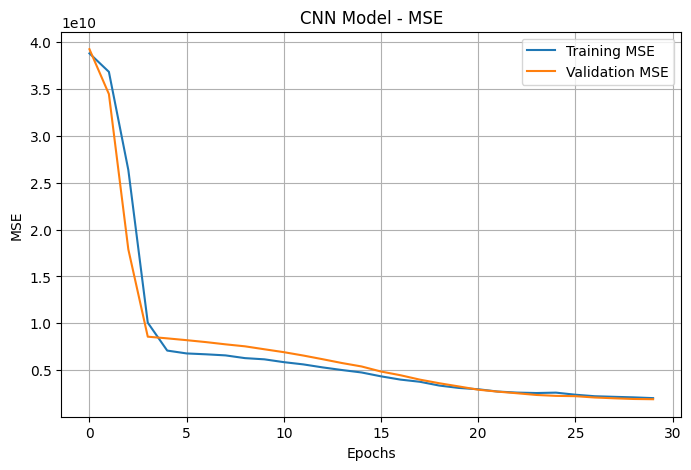

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training MSE')
plt.plot(history.history['val_loss'], label='Validation MSE')

plt.xlabel('Epochs')
plt.ylabel('MSE')
plt.title('CNN Model - MSE')
plt.legend()
plt.grid()
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

y_pred = model.predict(X_val).flatten()

mse = mean_squared_error(y_val, y_pred)
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_pred)

print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
MSE: 1902648576.0
MAE: 29997.828125
RMSE: 43619.36010534772
R2 Score: 0.7519468665122986


In [ ]:
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score, confusion_matrix
import numpy as np

# تعیین مرز گروه‌های قیمتی
q1, q2 = np.quantile(y_train, [0.33, 0.66])

# تبدیل قیمت واقعی و پیش‌بینی‌شده به سه گروه
y_true_class = np.digitize(y_val, [q1, q2])
y_pred_class = np.digitize(y_pred, [q1, q2])

# محاسبه معیارها
print("Accuracy:", accuracy_score(y_true_class, y_pred_class))
print("Precision:", precision_score(y_true_class, y_pred_class, average='weighted', zero_division=0))
print("Recall:", recall_score(y_true_class, y_pred_class, average='weighted', zero_division=0))
print("F1-score:", f1_score(y_true_class, y_pred_class, average='weighted', zero_division=0))

# ماتریس ابهام
cm = confusion_matrix(y_true_class, y_pred_class)

print("Confusion Matrix:")
print(cm)

Accuracy: 0.7534246575342466
Precision: 0.7560007452832481
Recall: 0.7534246575342466
F1-score: 0.7543064440026919
Confusion Matrix:
[[90 17  3]
 [23 54 10]
 [ 1 18 76]]


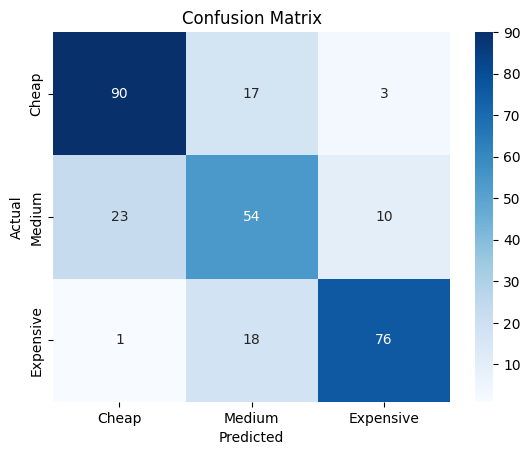

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Cheap', 'Medium', 'Expensive'],
    yticklabels=['Cheap', 'Medium', 'Expensive']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, MaxPooling1D
from sklearn.metrics import mean_squared_error
import numpy as np

results = []

for layers in [1, 2, 3]:

    model_test = Sequential()

    model_test.add(Conv1D(32, 3, activation='relu',
                          input_shape=(X_train.shape[1], 1)))

    if layers >= 2:
        model_test.add(Conv1D(64, 3, activation='relu'))

    if layers >= 3:
        model_test.add(Conv1D(128, 3, activation='relu'))

    model_test.add(Flatten())
    model_test.add(Dense(64, activation='relu'))
    model_test.add(Dense(1))

    model_test.compile(optimizer='adam', loss='mse')

    model_test.fit(
        X_train, y_train,
        epochs=10,
        batch_size=32,
        verbose=0
    )

    pred = model_test.predict(X_val, verbose=0).flatten()

    mse = mean_squared_error(y_val, pred)

    results.append([layers, mse])

    print("CNN Layers:", layers, "| MSE:", mse)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN Layers: 1 | MSE: 13675339776.0


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN Layers: 2 | MSE: 6336253440.0


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN Layers: 3 | MSE: 1935417216.0


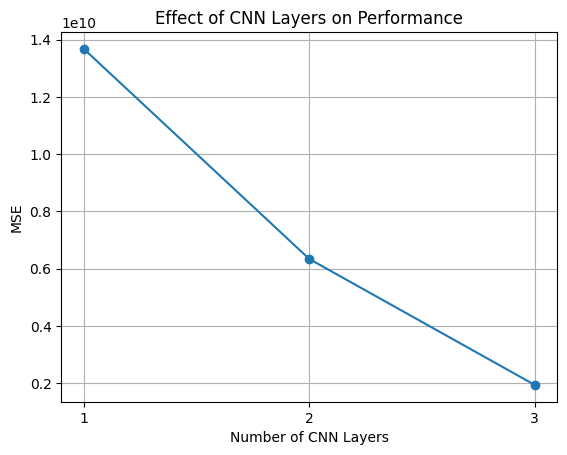

In [ ]:
import matplotlib.pyplot as plt

layers = [r[0] for r in results]
errors = [r[1] for r in results]

plt.plot(layers, errors, marker='o')
plt.xlabel('Number of CNN Layers')
plt.ylabel('MSE')
plt.title('Effect of CNN Layers on Performance')
plt.xticks([1, 2, 3])
plt.grid()
plt.show()

In [ ]:
predictions = model.predict(X_test).flatten()

submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': predictions
})

submission.to_csv('submission.csv', index=False)

print(submission.head())
print("Submission file created!")

46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
     Id      SalePrice
0  1461   90749.093750
1  1462  133909.296875
2  1463  146688.734375
3  1464  174050.765625
4  1465  173238.265625
Submission file created!


In [ ]:
from google.colab import files
files.download('submission.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, MaxPooling1D
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

results = []
histories = []

for n in [1, 2, 3]:

    m = Sequential()
    m.add(Conv1D(32, 3, activation='relu',
                 input_shape=(X_train.shape[1], 1)))

    if n >= 2:
        m.add(Conv1D(64, 3, activation='relu'))

    if n >= 3:
        m.add(Conv1D(128, 3, activation='relu'))

    m.add(Flatten())
    m.add(Dense(64, activation='relu'))
    m.add(Dense(1))

    m.compile(optimizer='adam', loss='mse')

    h = m.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=20,
        batch_size=32,
        verbose=0
    )

    p = m.predict(X_val, verbose=0).flatten()
    error = mean_squared_error(y_val, p)

    results.append(error)
    histories.append(h)

    print(f"{n} CNN Layers - MSE: {error:.2f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1 CNN Layers - MSE: 6631389184.00


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2 CNN Layers - MSE: 1736939392.00


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3 CNN Layers - MSE: 1338732416.00


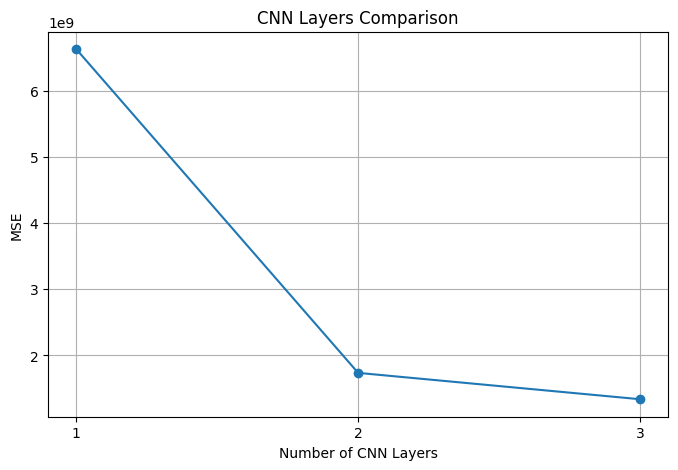

In [ ]:
plt.figure(figsize=(8,5))

plt.plot([1,2,3], results, marker='o')

plt.xlabel('Number of CNN Layers')
plt.ylabel('MSE')
plt.title('CNN Layers Comparison')
plt.xticks([1,2,3])
plt.grid()
plt.show()

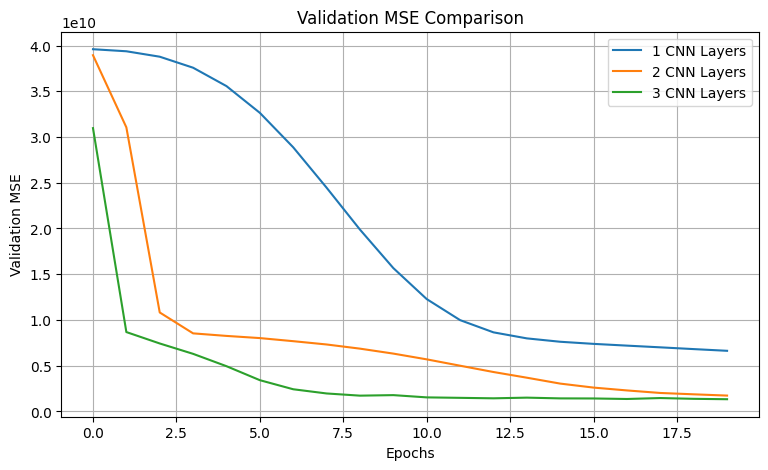

In [ ]:
plt.figure(figsize=(9,5))

for i, h in enumerate(histories):
    plt.plot(h.history['val_loss'],
             label=f'{i+1} CNN Layers')

plt.xlabel('Epochs')
plt.ylabel('Validation MSE')
plt.title('Validation MSE Comparison')
plt.legend()
plt.grid()
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'CNN Layers': [1, 2, 3],
    'MSE': results
})

print(comparison)

   CNN Layers           MSE
0           1  6.631389e+09
1           2  1.736939e+09
2           3  1.338732e+09
